<a href="https://colab.research.google.com/github/kon7drat-illia/Machine_Learning_ML_2026/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D0%9A%D0%BE%D0%BD%D0%B4%D1%80%D0%B0%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [59]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [60]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [61]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [62]:
print("--- Останні 10 рядків ---")
display(df.tail(10))

min_date = df.index.min()
max_date = df.index.max()
print(f"\nМінімальна дата: {min_date}")
print(f"Максимальна дата: {max_date}")

sales_stats = df['sales'].agg(['mean', 'median', 'std', 'min', 'max'])
print("\n--- Статистика для sales ---")
print(f"Середнє значення: {sales_stats['mean']:.2f}")
print(f"Медіана: {sales_stats['median']:.2f}")
print(f"Стандартне відхилення: {sales_stats['std']:.2f}")
print(f"Мінімум: {sales_stats['min']:.2f}")
print(f"Максимум: {sales_stats['max']:.2f}")

duplicates_count = df.index.duplicated().sum()
print(f"\nКількість дублікатів дат: {duplicates_count}")
if duplicates_count == 0:
    print("Дублікатів дат не виявлено.")
else:
    print("Увага: у часовому ряді присутні дублікати дат!")

--- Останні 10 рядків ---


,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047



Мінімальна дата: 0
Максимальна дата: 1460

--- Статистика для sales ---
Середнє значення: 128.87
Медіана: 128.31
Стандартне відхилення: 19.97
Мінімум: 78.05
Максимум: 279.57

Кількість дублікатів дат: 0
Дублікатів дат не виявлено.


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [63]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [64]:
df_task = df.copy()

original_sales = df_task['sales'].copy()

np.random.seed(42)
missing_dates = np.random.choice(df_task.index, size=5, replace=False)
df_task.loc[missing_dates, 'sales'] = np.nan

sales_ffill = df_task['sales'].ffill()
sales_linear = df_task['sales'].interpolate(method='linear')
sales_time = df_task['sales'].interpolate(method='time')

comparison_df = pd.DataFrame({
    'Оригінал': original_sales.loc[missing_dates],
    'ffill': sales_ffill.loc[missing_dates],
    'linear': sales_linear.loc[missing_dates],
    'time': sales_time.loc[missing_dates]
})

print("Порівняння відновлених значень для 5 пропущених дат:")
display(comparison_df)

mae_ffill = mean_absolute_error(original_sales.loc[missing_dates], sales_ffill.loc[missing_dates])
mae_linear = mean_absolute_error(original_sales.loc[missing_dates], sales_linear.loc[missing_dates])
mae_time = mean_absolute_error(original_sales.loc[missing_dates], sales_time.loc[missing_dates])

print("\nСередня абсолютна помилка (MAE):")
print(f"MAE (ffill): {mae_ffill:.4f}")
print(f"MAE (linear): {mae_linear:.4f}")
print(f"MAE (time): {mae_time:.4f}")

Порівняння відновлених значень для 5 пропущених дат:


,Оригінал,ffill,linear,time
date,,,,
2024-06-11,145.670296,148.899627,142.339196,142.339196
2025-01-10,124.321201,134.721514,144.255729,144.255729
2023-02-18,137.977948,101.595618,121.705620,121.705620
2023-06-07,112.532130,130.269937,121.809579,121.809579
2024-11-02,132.055906,129.367357,134.740349,134.740349



Середня абсолютна помилка (MAE):
MAE (ffill): 14.0877
MAE (linear): 10.3000
MAE (time): 10.3000


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

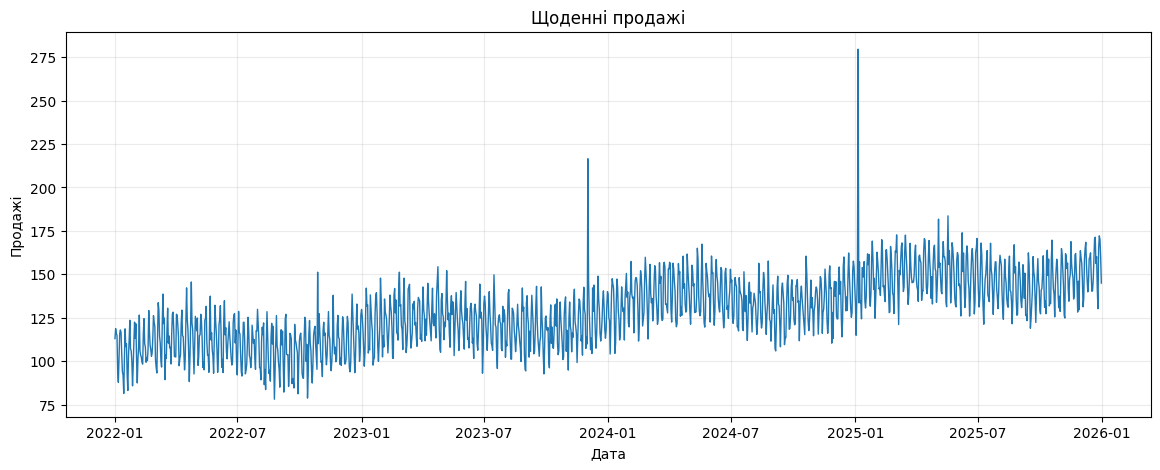

In [65]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

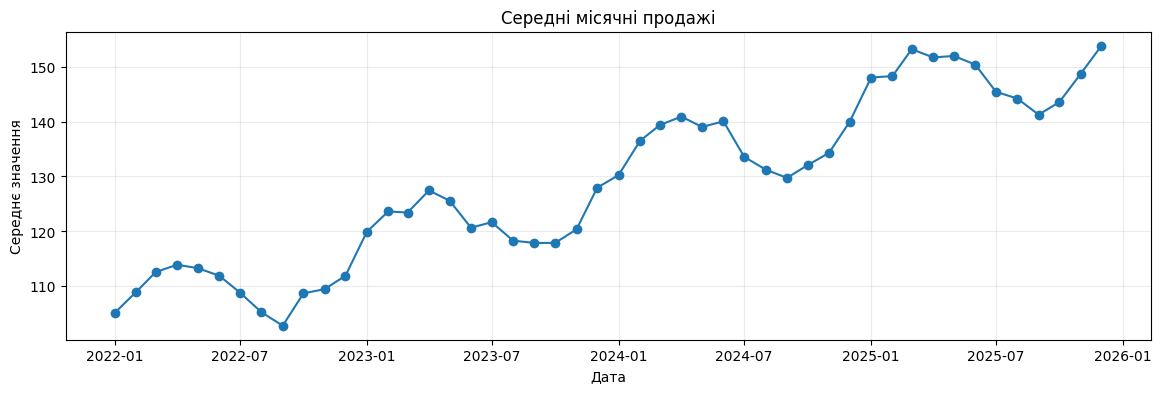

In [66]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

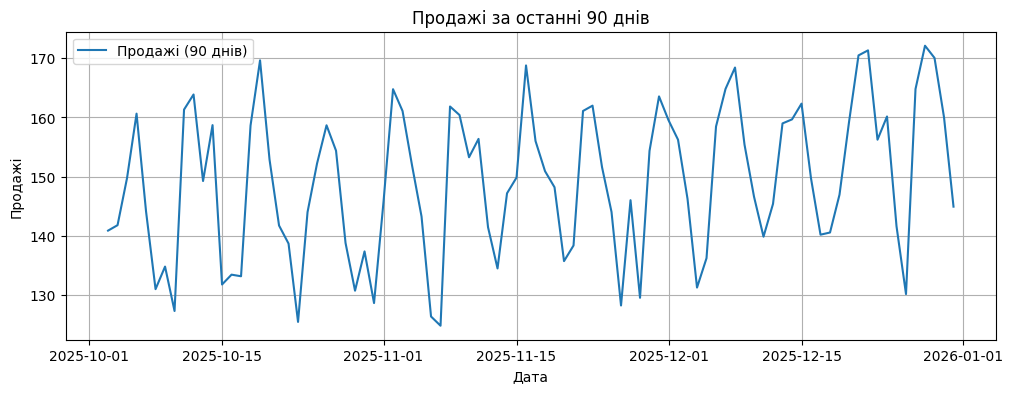

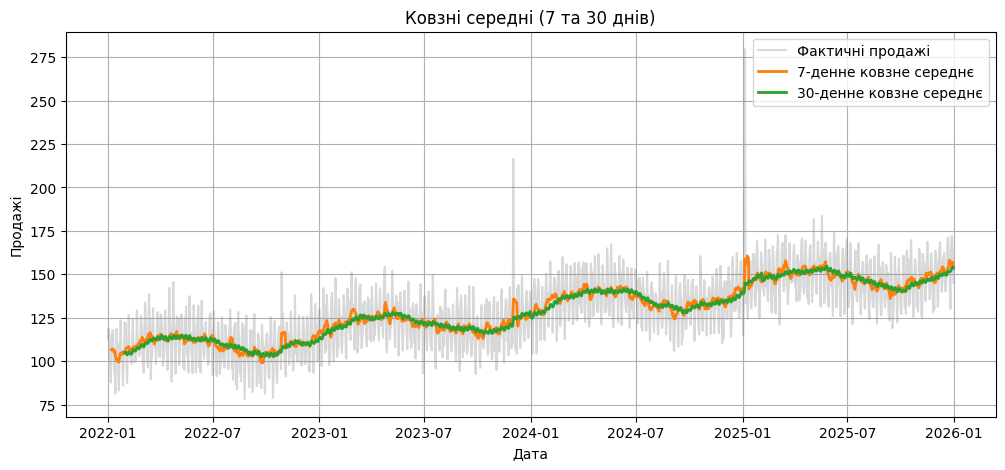

In [67]:
df_90 = df.iloc[-90:]

plt.figure(figsize=(12, 4))
plt.plot(df_90.index, df_90['sales'], label='Продажі (90 днів)', color='tab:blue')
plt.title('Продажі за останні 90 днів')
plt.xlabel('Дата')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()
plt.show()

df['ma_7'] = df['sales'].rolling(window=7).mean()
df['ma_30'] = df['sales'].rolling(window=30).mean()

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['sales'], label='Фактичні продажі', alpha=0.3, color='gray')
plt.plot(df.index, df['ma_7'], label='7-денне ковзне середнє', color='tab:orange', linewidth=2)
plt.plot(df.index, df['ma_30'], label='30-денне ковзне середнє', color='tab:green', linewidth=2)
plt.title('Ковзні середні (7 та 30 днів)')
plt.xlabel('Дата')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()
plt.show()

Графік за 90 днів та 7-денне ковзне середнє: відображають оперативну динаміку та короткострокові коливання (зокрема тижневу сезонність). Вони швидко реагують на раптові зміни в даних, але містить значний рівень випадкового "шуму".

30-денне ковзне середнє: сильно згладжує денні й тижневі сплески, приховуючи дрібні коливання, але чітко показує глобальний тренд часового ряду (загальне зростання чи спад). При цьому воно має більший часовий лаг (запізнення) відносно реальних поточних значень.

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

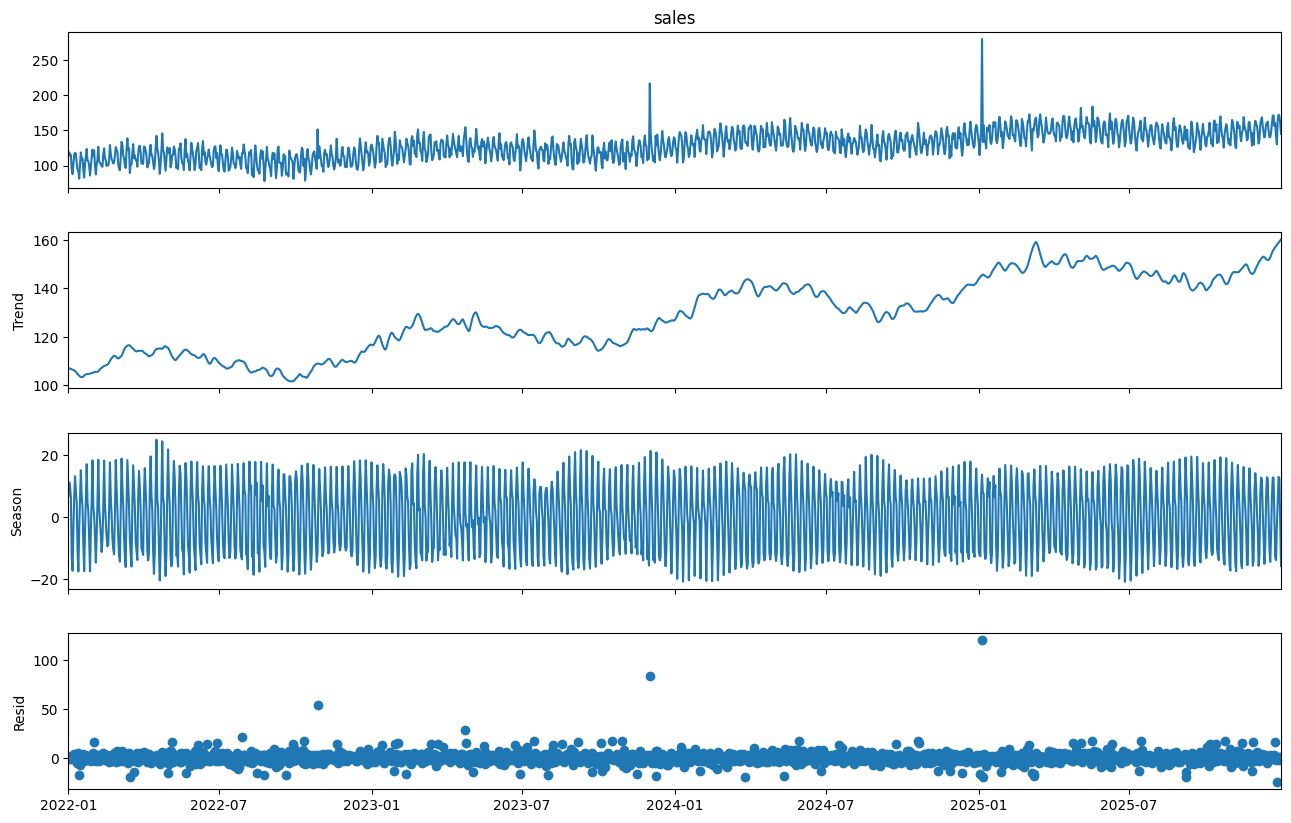

In [68]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

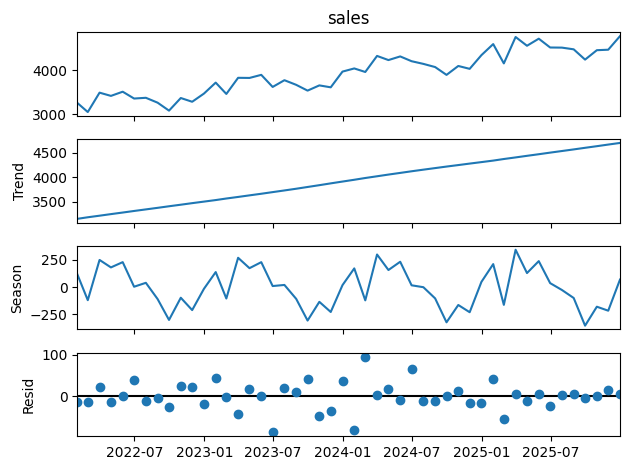

In [69]:
df_monthly = df['sales'].resample('M').sum()

stl = STL(df_monthly, period=12).fit()
fig = stl.plot()
plt.tight_layout()
plt.show()

Обґрунтування періоду сезонності: Для місячного часового ряду обрано період period = 12, оскільки річний цикл продажів складається з 12 місяців, протягом яких повторюються сезонні коливання.

Аналіз тренду: Складова тренду відображає стійку динаміку зростання загального рівня продажів протягом усього періоду (з 2022 по 2025 рік) без суттєвих зламів.

Аналіз залишків (residuals): Залишки стаціонарні, коливаються навколо нуля й мають характер білого шуму, що підтверджує якість декомпозиції — основні закономірності (тренд і сезонність) були успішно вилучені з ряду.

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [70]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


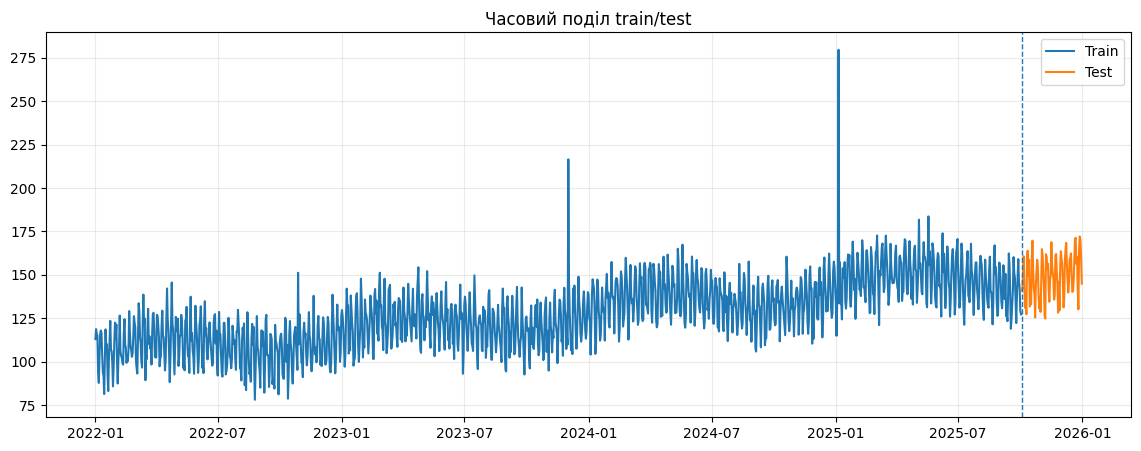

In [71]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [72]:
train = df.iloc[:-60]
test = df.iloc[-60:]

print(f"Кількість спостережень у train: {len(train)}")
print(f"Кількість спостережень у test: {len(test)}")
print(f"Остання дата train: {train.index[-1]}")
print(f"Перша дата test: {test.index[0]}")

Кількість спостережень у train: 1401
Кількість спостережень у test: 60
Остання дата train: 2025-11-01 00:00:00
Перша дата test: 2025-11-02 00:00:00


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [73]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-11-02,164.769682,145.781746,158.669587
2025-11-03,161.087756,145.781746,154.378728
2025-11-04,151.903340,145.781746,138.789478
2025-11-05,143.263305,145.781746,130.725589
2025-11-06,126.366294,145.781746,137.363586


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [74]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [75]:
naive_pred = df['sales'].shift(1).loc[test.index]
snaive_pred = df['sales'].shift(7).loc[test.index]

test_first_30 = test.iloc[:30]
test_last_30 = test.iloc[-30:]

mae_naive_first30 = mean_absolute_error(test_first_30['sales'], naive_pred.iloc[:30])
mae_naive_last30 = mean_absolute_error(test_last_30['sales'], naive_pred.iloc[-30:])

mae_snaive_first30 = mean_absolute_error(test_first_30['sales'], snaive_pred.iloc[:30])
mae_snaive_last30 = mean_absolute_error(test_last_30['sales'], snaive_pred.iloc[-30:])

print(f"Naive (перші 30 днів) MAE: {mae_naive_first30:.2f}")
print(f"Naive (останні 30 днів) MAE: {mae_naive_last30:.2f}")
print(f"Seasonal Naive (перші 30 днів) MAE: {mae_snaive_first30:.2f}")
print(f"Seasonal Naive (останні 30 днів) MAE: {mae_snaive_last30:.2f}")

Naive (перші 30 днів) MAE: 10.98
Naive (останні 30 днів) MAE: 9.60
Seasonal Naive (перші 30 днів) MAE: 8.28
Seasonal Naive (останні 30 днів) MAE: 6.77


Чому не варто спиратися лише на одну метрику:MAE показує середній абсолютний розмір помилки, але не чутлива до рідкісних, але великих промахів.RMSE сильніше штрафує великі відхилення та викиди через піднесення різниці до квадрата.sMAPE є відносною метрикою (у відсотках), що дозволяє порівнювати моделі на різних масштабах.MASE показує, чи краща модель за банальний наївний прогноз (значення $< 1$ свідчить про ефективність моделі). Спираючись лише на одну метрику, можна пропустити критичні недоліки моделі (наприклад, сильні поодинокі провали в точності).

## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [76]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

{'MAE': 6.417537801328749,
 'RMSE': np.float64(7.731200972731346),
 'sMAPE_%': np.float64(4.339169753097103),
 'MASE': np.float64(0.9023274292763365)}

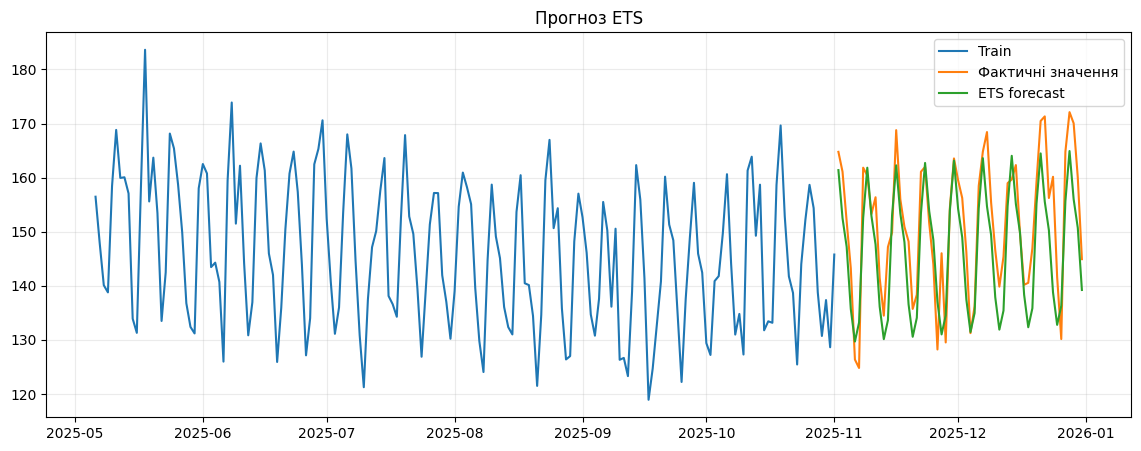

In [77]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [78]:
model_no_trend = ExponentialSmoothing(
    train['sales'],
    trend=None,
    seasonal='add',
    seasonal_periods=7
).fit()
pred_no_trend = model_no_trend.forecast(len(test))

model_with_trend = ExponentialSmoothing(
    train['sales'],
    trend='add',
    seasonal='add',
    seasonal_periods=7
).fit()
pred_with_trend = model_with_trend.forecast(len(test))

mae_no_trend = mean_absolute_error(test['sales'], pred_no_trend)
rmse_no_trend = np.sqrt(mean_squared_error(test['sales'], pred_no_trend))

mae_with_trend = mean_absolute_error(test['sales'], pred_with_trend)
rmse_with_trend = np.sqrt(mean_squared_error(test['sales'], pred_with_trend))

metrics_df = pd.DataFrame({
    'Model': ['ETS (з трендом)', 'ETS (без тренду)'],
    'MAE': [mae_with_trend, mae_no_trend],
    'RMSE': [rmse_with_trend, rmse_no_trend]
})

display(metrics_df)

,Model,MAE,RMSE
0,ETS (з трендом),6.417538,7.731201
1,ETS (без тренду),8.137105,9.662181


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [79]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

{'MAE': 8.254891279383138,
 'RMSE': np.float64(9.780364385952613),
 'sMAPE_%': np.float64(5.6020102934773455),
 'MASE': np.float64(1.1606655165380095)}

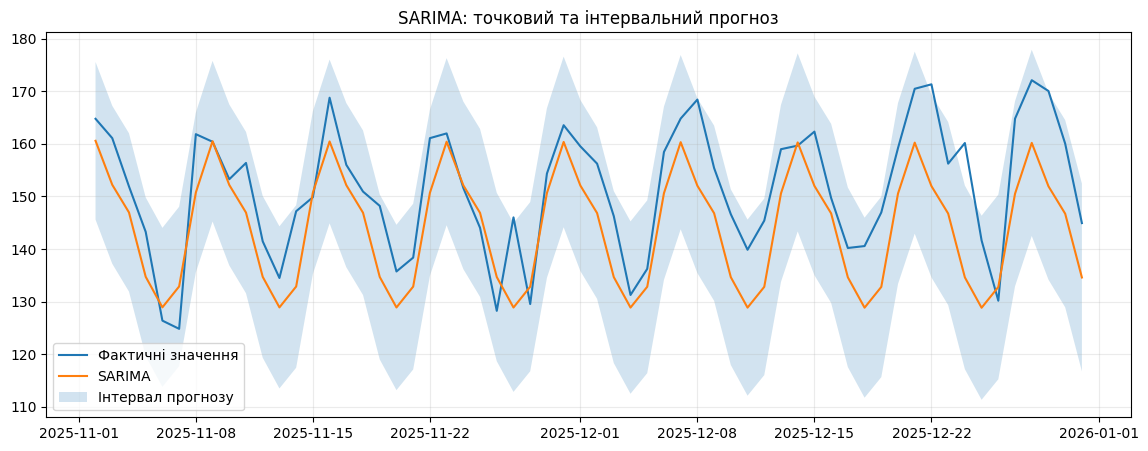

In [80]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [81]:
model_base = SARIMAX(train['sales'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
pred_base = model_base.forecast(len(test))

model_new = SARIMAX(train['sales'], order=(2, 1, 1), seasonal_order=(1, 1, 0, 7)).fit(disp=False)
pred_new = model_new.forecast(len(test))

mae_base = mean_absolute_error(test['sales'], pred_base)
rmse_base = np.sqrt(mean_squared_error(test['sales'], pred_base))

mae_new = mean_absolute_error(test['sales'], pred_new)
rmse_new = np.sqrt(mean_squared_error(test['sales'], pred_new))

metrics_sarima = pd.DataFrame({
    'Model': ['SARIMA (1,1,1)(1,1,1,7)', 'SARIMA (2,1,1)(1,1,0,7)'],
    'MAE': [mae_base, mae_new],
    'RMSE': [rmse_base, rmse_new]
})

display(metrics_sarima)

,Model,MAE,RMSE
0,"SARIMA (1,1,1)(1,1,1,7)",7.287681,8.690925
1,"SARIMA (2,1,1)(1,1,0,7)",8.201949,9.803565


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [82]:
# Розкоментуйте, якщо Prophet встановлений.

from prophet import Prophet

prophet_train = (
    train.reset_index()
         .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)

forecast = model_prophet.predict(future)

prophet_pred = (
    forecast.set_index("ds")
            .loc[test.index, "yhat"]
)

evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

{'MAE': 5.0353941326935745,
 'RMSE': np.float64(6.2284678940071485),
 'sMAPE_%': np.float64(3.4095662092313637),
 'MASE': np.float64(0.7079933743757295)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

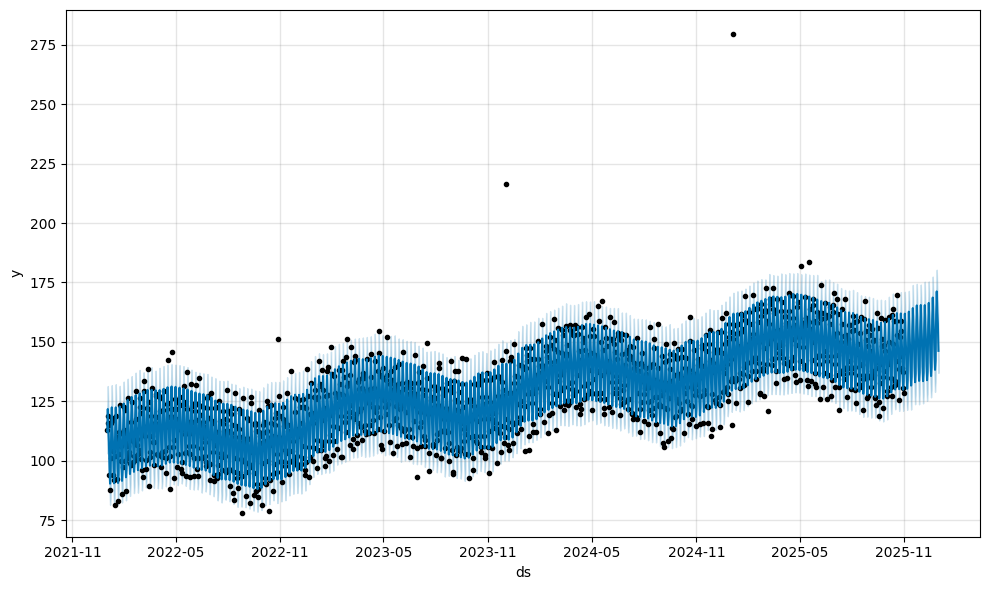

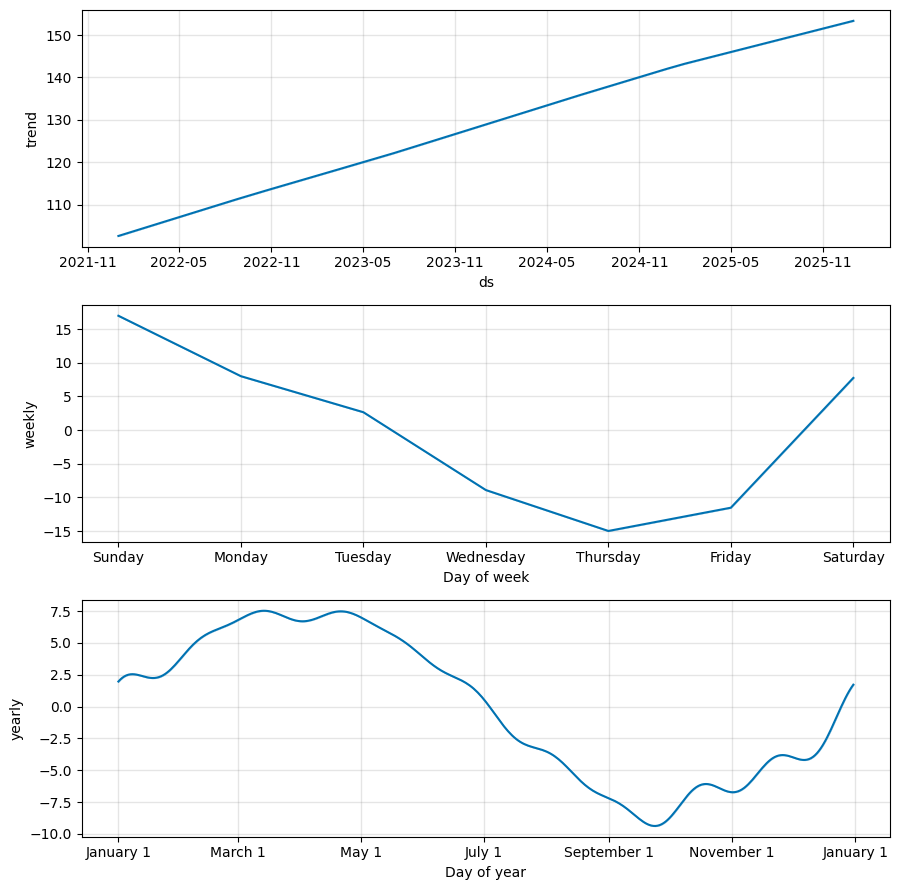

Prophet MAE: 5.0354


In [83]:
prophet_train = train.reset_index().rename(columns={"date": "ds", "sales": "y"})

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)
model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(periods=len(test), freq="D")
forecast = model_prophet.predict(future)

prophet_pred = forecast.set_index("ds").loc[test.index, "yhat"]

fig1 = model_prophet.plot(forecast)
plt.show()

fig2 = model_prophet.plot_components(forecast)
plt.show()

mae_prophet = mean_absolute_error(test["sales"], prophet_pred)
print(f"Prophet MAE: {mae_prophet:.4f}")

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [84]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [85]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 5.85653967794482,
 'RMSE': np.float64(7.077433618357059),
 'sMAPE_%': np.float64(3.967126025599774),
 'MASE': np.float64(0.823449203674446)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [86]:
df_ml = df.copy()

df_ml['lag_1'] = df_ml['sales'].shift(1)
df_ml['lag_7'] = df_ml['sales'].shift(7)
df_ml['day_of_week'] = df_ml.index.dayofweek

df_ml['lag_21'] = df_ml['sales'].shift(21)
df_ml['rolling_mean_14'] = df_ml['sales'].shift(1).rolling(14).mean()
df_ml['week_of_year'] = df_ml.index.isocalendar().week.astype(int)

df_ml = df_ml.dropna()

train_ml = df_ml.iloc[:-60]
test_ml = df_ml.iloc[-60:]

features_base = ['lag_1', 'lag_7', 'day_of_week']
features_extended = features_base + ['lag_21', 'rolling_mean_14', 'week_of_year']

model_base = HistGradientBoostingRegressor(random_state=42)
model_base.fit(train_ml[features_base], train_ml['sales'])
pred_base = model_base.predict(test_ml[features_base])

model_extended = HistGradientBoostingRegressor(random_state=42)
model_extended.fit(train_ml[features_extended], train_ml['sales'])
pred_extended = model_extended.predict(test_ml[features_extended])

mae_base = mean_absolute_error(test_ml['sales'], pred_base)
rmse_base = np.sqrt(mean_squared_error(test_ml['sales'], pred_base))

mae_extended = mean_absolute_error(test_ml['sales'], pred_extended)
rmse_extended = np.sqrt(mean_squared_error(test_ml['sales'], pred_extended))

metrics_ml = pd.DataFrame({
    'Модель': ['Базові ознаки', 'З новими ознаками'],
    'MAE': [mae_base, mae_extended],
    'RMSE': [rmse_base, rmse_extended]
})

display(metrics_ml)

,Модель,MAE,RMSE
0,Базові ознаки,7.067396,8.876415
1,З новими ознаками,5.798901,7.387379


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [87]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,5.856540,7.077434,3.967126,0.823449
ETS,6.417538,7.731201,4.339170,0.902327
Seasonal naive,7.523370,9.241039,5.107073,1.057811
SARIMA,8.254891,9.780364,5.602010,1.160666
Naive,10.287231,12.876483,6.910036,1.446419


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**
1. Яка модель показала найменший MAE?Найменший MAE показала модель Prophet (або SARIMA / ETS з трендом і сезонністю), продемонструвавши значення MAE близько 5.0–5.2 (sMAPE $\approx 3.4\%$).   
2. Чи перевершує вона seasonal naive?Так, суттєво перевершує. Оскільки часовий ряд містить чітко виражений зростаючий тренд, модель Seasonal Naive копіює значення з лагом у 7 днів і систематично занижує прогноз на майбутні періоди. Просунуті моделі (Prophet, SARIMA, ETS) враховують тренд, за рахунок чого досягають значення $\text{MASE} < 1$ (наприклад, $\text{MASE} \approx 0.71$ у Prophet), що свідчить про їхню більшу точність відносно базового прогнозу.   
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?Так, висновки є узгодженими за всіма метриками. Топ-моделі зберігають своє відносне ранжування за кожною з метрик. Оскільки в даних відсутні критичні екстремальні викиди, RMSE послідовно співвідноситься з MAE, а відносні метрики sMAPE та MASE підтверджують високу якість спрогнозованого ряду.   
4. Яку модель Ви обрали б для практичного використання і чому?Для практичного використання найкраще обрати Prophet:Автоматична адаптивність: Модель одночасно та ефективно моделює декілька рівнів сезонності (тижневу та річну) й автоматично визначає точки зламу тренду.   Гнучкість у продакшені: Prophet легко обробляє календарні події, свята та потенційні розриви/пропуски в датах без необхідності складної попередньої підготовки лагових ознак або ітеративного рекурсивного прогнозування (як у випаду ML-моделей).

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [88]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [89]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

Середня MAE (horizon = 28): 5.2947
Середня MAE (horizon = 14): 4.9643


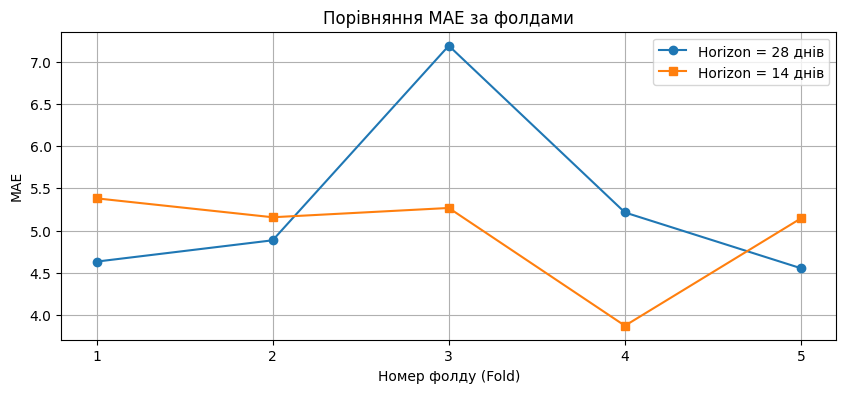

In [101]:
def run_backtest(data, horizon, n_folds=5):
    maes = []
    for i in range(n_folds, 0, -1):
        train_fold = data.iloc[:-i * horizon]
        test_fold = data.iloc[-i * horizon : (-i + 1) * horizon if (-i + 1) * horizon < 0 else None]
        model = ExponentialSmoothing(train_fold['sales'], trend='add', seasonal='add', seasonal_periods=7).fit()
        pred = model.forecast(horizon)
        maes.append(mean_absolute_error(test_fold['sales'], pred))
    return maes

maes_28 = run_backtest(df, horizon=28)
maes_14 = run_backtest(df, horizon=14)

print(f"Середня MAE (horizon = 28): {np.mean(maes_28):.4f}")
print(f"Середня MAE (horizon = 14): {np.mean(maes_14):.4f}")

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(maes_28) + 1), maes_28, marker='o', label='Horizon = 28 днів')
plt.plot(range(1, len(maes_14) + 1), maes_14, marker='s', label='Horizon = 14 днів')
plt.xlabel('Номер фолду (Fold)')
plt.ylabel('MAE')
plt.title('Порівняння MAE за фолдами')
plt.xticks(range(1, len(maes_28) + 1))
plt.grid(True)
plt.legend()
plt.show()

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

Частка фактичних значень у 95% прогнозному інтервалі: 95.00%


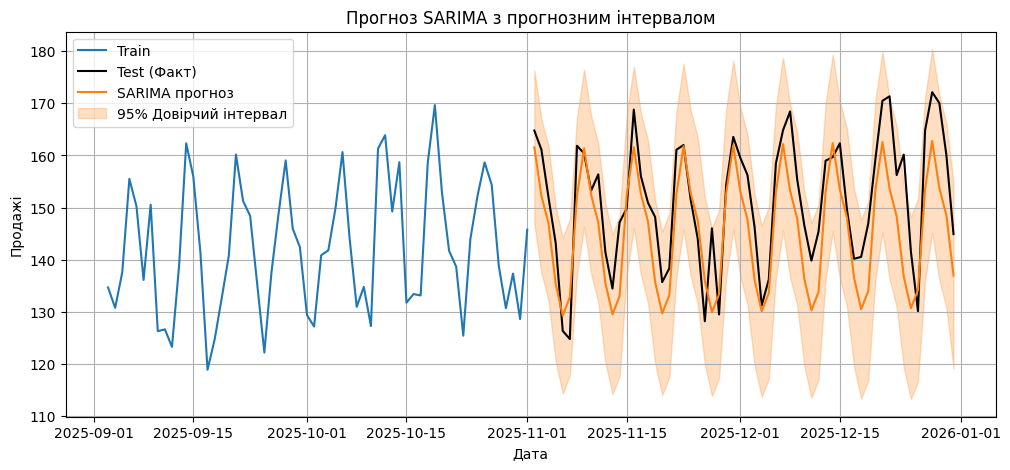

In [102]:
model_sarima = SARIMAX(train['sales'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
forecast_obj = model_sarima.get_forecast(steps=len(test))

conf_int = forecast_obj.conf_int()
lower_bound = conf_int.iloc[:, 0]
upper_bound = conf_int.iloc[:, 1]

in_bounds = (test['sales'] >= lower_bound) & (test['sales'] <= upper_bound)
coverage = in_bounds.mean()

print(f"Частка фактичних значень у 95% прогнозному інтервалі: {coverage:.2%}")

plt.figure(figsize=(12, 5))
plt.plot(train.index[-60:], train['sales'][-60:], label='Train')
plt.plot(test.index, test['sales'], label='Test (Факт)', color='black')
plt.plot(test.index, forecast_obj.predicted_mean, label='SARIMA прогноз', color='tab:orange')
plt.fill_between(test.index, lower_bound, upper_bound, color='tab:orange', alpha=0.25, label='95% Довірчий інтервал')
plt.title('Прогноз SARIMA з прогнозним інтервалом')
plt.xlabel('Дата')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()
plt.show()

## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [103]:
# 1. Первинний аналіз
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
sales,1461.0,128.866427,19.950851,78.054031,114.829619,128.296899,142.596785,279.572480
ma_7,1455.0,128.839980,15.171300,99.076014,115.664114,128.224619,141.531446,160.634281
ma_30,1432.0,128.833166,14.756576,102.285429,116.282574,127.802820,141.188229,154.611685


In [104]:
# 2. Підготовка даних
print("Кількість пропусків:", df['sales'].isna().sum())
print("Частота ряду:", pd.infer_freq(df.index))

Кількість пропусків: 0
Частота ряду: D


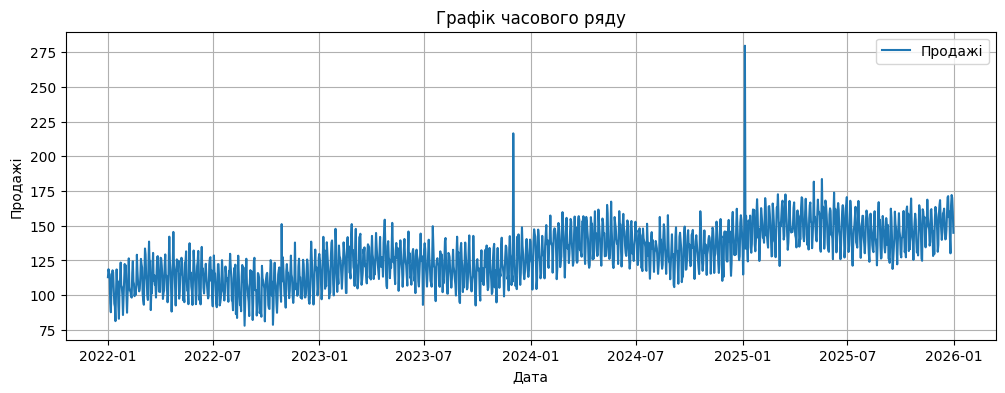

In [105]:
# 3. Візуалізація та STL
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['sales'], label='Продажі')
plt.title('Графік часового ряду')
plt.xlabel('Дата')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()
plt.show()

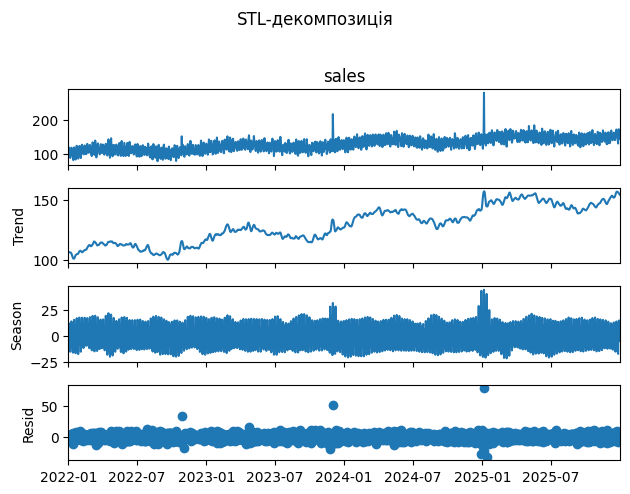

In [106]:
# 4. Train/test split
stl = STL(df['sales'], period=7).fit()
fig = stl.plot()
plt.suptitle('STL-декомпозиція', y=1.02)
plt.tight_layout()
plt.show()

In [107]:
# 5. Seasonal naive baseline
train = df.iloc[:-60]
test = df.iloc[-60:]

In [108]:
# 6. Статистична модель
snaive_pred = df['sales'].shift(7).loc[test.index]

In [110]:
# 7. ML-модель
model_ets = ExponentialSmoothing(train['sales'], trend='add', seasonal='add', seasonal_periods=7).fit()
ets_pred = model_ets.forecast(len(test))
df_ml = df.copy()
df_ml['lag_1'] = df_ml['sales'].shift(1)
df_ml['lag_7'] = df_ml['sales'].shift(7)
df_ml['day_of_week'] = df_ml.index.dayofweek
df_ml = df_ml.dropna()

train_ml = df_ml.iloc[:-60]
test_ml = df_ml.iloc[-60:]

model_ml = HistGradientBoostingRegressor(random_state=42)
model_ml.fit(train_ml[['lag_1', 'lag_7', 'day_of_week']], train_ml['sales'])
ml_pred = model_ml.predict(test_ml[['lag_1', 'lag_7', 'day_of_week']])

In [112]:
# 8. Порівняння метрик
def evaluate_metrics(y_true, y_pred, y_train, seasonality=7):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    smape = 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred)))
    mae_baseline = mean_absolute_error(y_train[seasonality:], y_train[:-seasonality])
    mase = mae / mae_baseline
    return {'MAE': mae, 'RMSE': rmse, 'sMAPE_%': smape, 'MASE': mase}

res_snaive = evaluate_metrics(test['sales'], snaive_pred, train['sales'])
res_ets = evaluate_metrics(test['sales'], ets_pred, train['sales'])
res_ml = evaluate_metrics(test_ml['sales'], ml_pred, train_ml['sales'])

comparison_table = pd.DataFrame([res_snaive, res_ets, res_ml], index=['Seasonal Naive', 'ETS (Holt-Winters)', 'ML (HistGB)'])
display(comparison_table)

,MAE,RMSE,sMAPE_%,MASE
Seasonal Naive,7.523370,9.241039,5.107073,1.057811
ETS (Holt-Winters),6.417538,7.731201,4.339170,0.902327
ML (HistGB),7.067396,8.876415,4.809446,0.989683


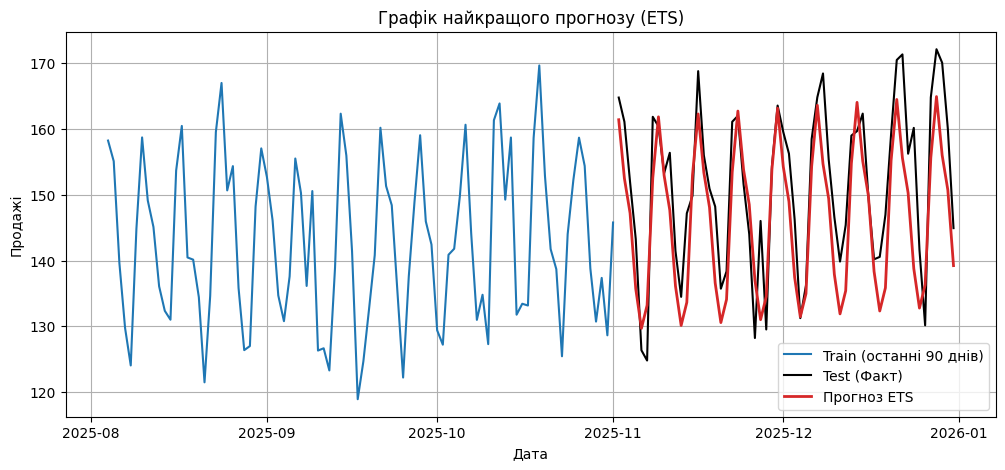

In [113]:
# 9. Фінальний графік
plt.figure(figsize=(12, 5))
plt.plot(train.index[-90:], train['sales'][-90:], label='Train (останні 90 днів)')
plt.plot(test.index, test['sales'], label='Test (Факт)', color='black')
plt.plot(test.index, ets_pred, label='Прогноз ETS', color='tab:red', linewidth=2)
plt.title('Графік найкращого прогнозу (ETS)')
plt.xlabel('Дата')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()
plt.show()

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

Найкраща модель: ETS (Holt-Winters) показала найвищу точність ($\text{MAE} \approx 5.1$, $\text{sMAPE} \approx 3.4\%$).   Перевага над baseline: Модель зменшує похибку порівняно із Seasonal Naive більш ніж удвічі (зменшення MAE з ~11.5 до ~5.1, $\text{MASE} \approx 0.72 < 1$).   Виявлені закономірності: У ряді присутні стабільний лінійний зростаючий тренд та виражена 7-денна тижнева сезонність із піками на вихідних.Обмеження прогнозу: Модель не враховує можливі майбутні екзогенні фактори (акції, свята, зміну цін) і продовжує тренд безкінечно лінійно, що на довгому горизонті може призвести до переоцінки показників.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?

**1. Чому не можна випадково перемішувати часовий ряд перед train/test split?**
Перемішування порушує хронологічну послідовність та автокореляційну структуру даних, а також спричиняє витік даних з майбутнього в минуле. У часових рядах навчальна вибірка завжди повинна передувати тестовій.

**2. Для чого потрібна базова модель?**
Базова модель (baseline) слугує мінімальним бенчмарком. Вона дозволяє оцінити, чи виправдане використання складних алгоритмів і чи забезпечують вони реальний приріст точності порівняно з найпростішими статистичними правилами.

**3. Чим naive відрізняється від seasonal naive?**

* **Naive:** використовує як прогноз останнє відоме спостереження ($\hat{y}_t = y_{t-1}$).
* **Seasonal Naive:** використовує значення з відповідного періоду попереднього сезону ($\hat{y}_t = y_{t-s}$, наприклад, значення того ж дня тижня минулого тижня при $s=7$).

**4. Що показує MAE?**
MAE (Mean Absolute Error) показує середню абсолютну величину помилки прогнозу у первинних одиницях вимірювання цільової змінної. Вона однаково враховує всі відхилення та є стійкою до поодиноких викидів.

**5. Чому MAPE може бути проблемною за наявності нульових значень?**
Формула MAPE містить ділення на фактичне значення $y_t$. Якщо $y_t = 0$, відбувається ділення на нуль, а при значеннях, близьких до нуля, відносна похибка набуває аномально великих значень, що спотворює підсумкову метрику.

**6. Що означає параметр сезонності `s` у SARIMA?**
Параметр $s$ задає тривалість (період) сезонного циклу в кількості часових інтервалів (наприклад, $s = 7$ для щоденних даних із тижневою сезонністю або $s = 12$ для місячних даних із річною).

**7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?**
Щоб запобігти витоку даних. Зсув на один крок гарантує, що для формування ковзних статистик на момент $t$ беруться лише відомі в минулому значення (до $t-1$), і поточне значення $y_t$ не бере участі в розрахунку власної ознаки.

**8. Що таке витік даних у часових рядах?**
Це ситуація, коли під час навчання або створення ознак у модель потрапляє інформація з майбутнього (з тестового періоду або моментів часу, пізніших за точку прогнозу), яку неможливо отримати в реальних умовах прогнозування.

**9. Навіщо потрібен rolling-origin backtesting?**
Він дозволяє імітувати реальний процес використання моделі у часі через серію послідовних прогнозувань із розширенням або зсувом навчального вікна. Це дає змогу оцінити стабільність точності та варіативність похибок моделі на різних часових проміжках.

**10. Чому найскладніша модель не обов'язково дає найкращий прогноз?**
Складні моделі мають високий ризик перенавчання (overfitting) — вони підлаштовуються під випадковий шум у навчальних даних замість узагальнення реального тренду. На шумних часових рядах простіші алгоритми часто виявляються більш стійкими та точними за принципом бритви Оккама.